# Kimi K3 From Scratch
### A progressive, executable guide to a tiny K3-inspired language model

**Language:** English · **Level:** intermediate to advanced · **Source check:** October 10, 2026
**Prerequisites:** Python, matrix multiplication, derivatives, and basic PyTorch.
**Status:** educational implementation; not compatible with official K3 checkpoints.

We will build a small decoder, train it on generated text, and generate new tokens. The purpose is to understand the equations well enough to implement and test them. Each executable cell is preceded by its concepts, mathematical details, tensor shapes, and a description of what to inspect. Run the notebook **from top to bottom in a fresh Python kernel**; later cells intentionally reuse earlier definitions.

### Why start here?
A language model must mix information across **tokens**, **depth**, and **features**. Keeping every token in full attention becomes expensive; putting every feature through every expert wastes compute; summing every layer output gives limited control over depth. We will encounter each problem before adding its corresponding mechanism.

### Verified model snapshot and scope
The [official repository](https://github.com/MoonshotAI/Kimi-K3) lists approximately 2.8T total / 104B active parameters, 93 layers (69 KDA and 24 gated MLA), 896 routed experts with 16 selected and two shared experts, a 160K vocabulary, and a 1,048,576-token context. It also identifies MoonViT-V2 and MXFP4/MXFP8 quantization.

| Component | This notebook | Fidelity boundary |
|---|---|---|
| Tokenizer | Small character vocabulary | Not the official tokenizer or chat template |
| KDA | Sequential recurrence, short convolution, bounded decay, output gate | No fused or chunk-parallel kernel |
| Global attention | Gated low-rank KV attention with NoPE | Simplified query projection; explicit KV reconstruction |
| Depth mixing | Block Attention Residuals | Small block size, not production partitioning |
| Experts | Latent routed experts, two full-width shared experts, SiTU-GLU | Tiny widths and expert count |
| Balancing | Exact local quantiles, delayed bias update | No distributed histogram approximation |
| Training | Float32 AdamW and synthetic text | No production optimizer, corpus, SFT, RL, or distillation |
| Vision | Separate patch-to-prefix interface exercise | Not MoonViT-V2; no visual understanding claim |

Architecture details are checked against the [K3 technical report, Section 2](https://arxiv.org/html/2607.24653v1#S2). This is a current K3-focused tutorial, not a claim that K3 is the newest model across all labs.

### Reading route
1. Tokens, labels, loss, and normalization.
2. Causal attention and its memory cost.
3. Delta-rule memory and a learnable KDA layer.
4. Compressed global attention and streaming caches.
5. Depth attention, sparse experts, and balancing.
6. A complete decoder, correctness checks, training, and generation.
7. Vision interface, trade-offs, exercises, and interview questions.

### Mental model
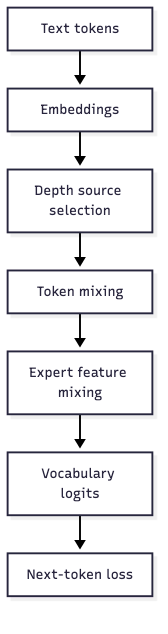
This diagram shows one conceptual pass. The code repeats depth selection before each token mixer and each feature mixer. The image is embedded in this notebook so it displays in Jupyter and VS Code without a Mermaid extension.

### Tested execution and quick start

All 31 code cells executed successfully in a fresh CPU kernel with Python 3.12.8, PyTorch 2.14.1, and Matplotlib 3.11.2. The current reference run takes about 10 seconds overall, including about 4 seconds of training; the saved outputs below are regenerated for this version. Hardware and package versions affect runtime. The model has 73,198 trainable parameters and runs on a CPU. Saved outputs are real execution results.

To create an independent environment from a terminal:

```bash
python3 -m venv .venv
source .venv/bin/activate
python -m pip install torch==2.14.1 matplotlib==3.11.2 ipykernel
python -m ipykernel install --user --name tiny-k3 --display-name "Python (Tiny K3)"
```

Open this file in a Jupyter-compatible editor, choose that kernel, and use **Restart Kernel and Run All**. On Windows, activate with `.venv\Scripts\activate` instead. The first code cell imports packages but does not install anything. The checkpoint cell writes a small file under `artifacts/` in the execution directory.


## 1. Environment and reproducibility

We use only PyTorch for model computation and Matplotlib for figures. The notebook downloads no model weights or dataset and makes no API calls. A CPU is sufficient for the tiny defaults. Sequential Python recurrence is intentionally easy to inspect but is not a production throughput implementation.

If imports fail, install `torch matplotlib ipykernel` in your selected environment, then restart the kernel. The delivered outputs record the actual tested versions. We set the pseudorandom seed so initialization and sampling are repeatable on the same software and hardware. Different kernels and floating-point implementations can still produce small differences.

**Inspect:** the Python/PyTorch versions and the device. Float32 is deliberate: first establish numerical correctness, then investigate reduced precision.

In [1]:
import math, random, sys, time
from dataclasses import dataclass, asdict
from pathlib import Path
import torch
from torch import nn
import torch.nn.functional as F
import matplotlib.pyplot as plt

SEED = 23
random.seed(SEED)
torch.manual_seed(SEED)
torch.set_num_threads(2)
DEVICE = torch.device('cpu')
print('Python:', sys.version.split()[0])
print('PyTorch:', torch.__version__)
print('Device:', DEVICE)

Python: 3.12.8
PyTorch: 2.14.1
Device: cpu


## 2. Make a small dataset before making a large model

A model learns a distribution from examples; architecture alone does not supply knowledge. We generate short records from a tiny grammar. Documents are split **before** token windows are sampled, and exact duplicate documents are removed. This prevents an identical full document from appearing in both splits, although vocabulary and grammatical templates intentionally overlap. Validation measures generalization within this artificial grammar, not real-world language understanding.

A character tokenizer maps each symbol to an integer in $\{0,\ldots,V-1\}$. Its simplicity makes label alignment visible. A production subword tokenizer usually represents frequent strings with fewer tokens; token counts and perplexities across different tokenizers cannot be compared directly.

**Shapes:** each encoded document is a one-dimensional integer tensor. The vocabulary is defined from the known synthetic alphabet, not inferred by fitting on validation outcomes. **Inspect:** document counts, vocabulary size, and an exact encode/decode round trip.

In [2]:
nouns = ['robot', 'student', 'teacher', 'scientist', 'artist', 'engineer']
verbs = ['reads', 'writes', 'tests', 'builds', 'checks', 'studies']
objects = ['code', 'math', 'a model', 'a book', 'a program', 'a theory']
documents = sorted({f'the {n} {v} {o}.\n' for n in nouns for v in verbs for o in objects})
rng = random.Random(SEED)
rng.shuffle(documents)
split = int(0.85 * len(documents))
train_docs, val_docs = documents[:split], documents[split:]
assert set(train_docs).isdisjoint(val_docs)
alphabet = sorted(set('abcdefghijklmnopqrstuvwxyz .\n'))
stoi = {c: i for i, c in enumerate(alphabet)}
itos = dict(enumerate(alphabet))
PAD_ID = len(alphabet)
V = PAD_ID + 1
def encode(text): return torch.tensor([stoi[c] for c in text], dtype=torch.long)
def decode(ids): return ''.join(itos[int(i)] for i in ids if int(i) != PAD_ID)
def show_tokens(ids): return ' '.join('<PAD>' if int(i) == PAD_ID else repr(itos[int(i)]) for i in ids)
train_tokens = [encode(s) for s in train_docs]
val_tokens = [encode(s) for s in val_docs]
assert decode(encode(train_docs[0])) == train_docs[0]
print('Train/validation documents:', len(train_docs), len(val_docs))
print('Character vocabulary:', len(alphabet), '+ one PAD ID =', V)
print('Example:', repr(train_docs[0]))

Train/validation documents: 183 33
Character vocabulary: 29 + one PAD ID = 30
Example: 'the teacher tests code.\n'


## 3. Shift targets, then left-pad variable-length examples

For an unpadded sequence $(x_0,\ldots,x_L)$, the input is $(x_0,\ldots,x_{L-1})$ and the target is $(x_1,\ldots,x_L)$. The logit for input $x_t$ predicts the **next** symbol $x_{t+1}$. A causal attention diagonal may include $x_t$ because it is not the target.

A minibatch must be rectangular, but its examples need not all have the same length. We sample windows with lengths from 6 to 16. For a window of length $L\leq T$, place $T-L$ PAD IDs **before** both the input and the target. For example, a length-three input `[a,b,c]` and targets `[b,c,d]` become `[PAD,PAD,a,b,c]` and `[PAD,PAD,b,c,d]` when $T=5$. We pad both sides of the shifted pair by the same amount so every real logit retains its next-token label.

We sample windows within individual documents, never across the train/validation split. Each eligible document is sampled uniformly before its window start is sampled; this is not uniform sampling over all corpus tokens. `PAD_ID` is a separate vocabulary entry, never a character in the raw documents. We display it explicitly to make the direction of padding visible.

**Shapes:** inputs, targets, and the validity mask have shape $[B,T]$. Every row of the mask is zeros followed by ones. **Inspect:** different rows have different real lengths, all padding appears on the left, and the target shift holds wherever both positions are real.

> **Interview insight:** A low loss is meaningless if targets are not shifted or padding positions are counted as real labels. Check both alignment and the loss denominator.

In [3]:
BATCH, SEQ = 8, 16
MIN_LENGTH = 6
batch_rng = torch.Generator().manual_seed(SEED)
def get_batch(doc_list, batch_size=BATCH, length=SEQ, generator=batch_rng, min_length=MIN_LENGTH):
    if not 1 <= min_length <= length: raise ValueError('Invalid length range.')
    eligible = [d for d in doc_list if len(d) >= length + 1]
    if not eligible: raise ValueError('No document is long enough for this window.')
    lengths = torch.randint(min_length, length + 1, (batch_size,), generator=generator).tolist()
    if batch_size >= 2 and length > min_length:
        lengths[0], lengths[1] = min_length, length  # Guarantee visibly different lengths.
    inputs, targets = [], []
    for window_length in lengths:
        d = eligible[int(torch.randint(len(eligible), (1,), generator=generator))]
        start = int(torch.randint(len(d) - window_length, (1,), generator=generator))
        window = d[start:start + window_length + 1]
        pad = length - window_length
        # Drop the final token, left-pad to length, and add this input to the batch.
        inputs.append(F.pad(window[:-1], (pad, 0), value=PAD_ID))
        targets.append(F.pad(window[1:], (pad, 0), value=PAD_ID))
    x, y = torch.stack(inputs).to(DEVICE), torch.stack(targets).to(DEVICE)
    return x, y

xb, yb = get_batch(train_tokens)
valid = xb != PAD_ID
assert torch.equal(valid, yb != PAD_ID)
assert ((valid.int().diff(dim=1)) >= 0).all()  # No real token precedes a PAD token.
shift_valid = yb[:, :-1] != PAD_ID
assert torch.equal(xb[:, 1:][shift_valid], yb[:, :-1][shift_valid])
assert len(set(valid.sum(1).tolist())) > 1
print('Input/target shape:', tuple(xb.shape))
print('Real lengths:', valid.sum(1).tolist())
print('Example input: ', show_tokens(xb[0]))
print('Example target:', show_tokens(yb[0]))

Input/target shape: (8, 16)
Real lengths: [6, 16, 15, 8, 10, 6, 11, 6]
Example input:  <PAD> <PAD> <PAD> <PAD> <PAD> <PAD> <PAD> <PAD> <PAD> <PAD> ' ' 'r' 'e' 'a' 'd' 's'
Example target: <PAD> <PAD> <PAD> <PAD> <PAD> <PAD> <PAD> <PAD> <PAD> <PAD> 'r' 'e' 'a' 'd' 's' ' '


## 4. Masked cross-entropy and the uniform baseline

The chain rule gives $p(x_{1:L}\mid x_0)=\prod_{t=0}^{L-1}p(x_{t+1}\mid x_{0:t})$. The network emits logits $z_{b,t,j}$ and softmax turns them into probabilities. With $m_{b,t}=1$ for real targets and $0$ for PAD, minimize
$$\mathcal L=-\frac{1}{\sum_{b,t}m_{b,t}}\sum_{b,t}m_{b,t}\left[z_{b,t,y_{b,t}}-\log\sum_{j=1}^{V}e^{z_{b,t,j}}\right].$$
The denominator counts **real targets**, not $BT$. We implement the formula directly: subtract the largest logit before exponentiating, compute the log normalization, select the correct token's score, and mask PAD targets. Subtracting the maximum leaves softmax unchanged and prevents exponential overflow. Padding in a target is therefore not a supervised prediction. The PAD class still occupies one output column; it is never a desired real target and is forbidden during generation.

**Why shift the logits?** At each token position, subtract that row's largest logit $M=\max_k z_k$ from every vocabulary score: $s_j=z_j-M$. For example, `[2, 5, 1]` becomes `[-3, 0, -4]`. Every shifted score is **non-positive**: the maximum becomes zero (including ties), and smaller scores become negative. The shape stays $[BT,V]$ because the row maxima have shape $[BT,1]$ and broadcast across vocabulary columns.

Shifting preserves the probabilities because the same factor $e^{-M}$ appears in the numerator and denominator and cancels:
$$\frac{e^{z_y-M}}{\sum_j e^{z_j-M}}=\frac{e^{-M}e^{z_y}}{e^{-M}\sum_j e^{z_j}}=\frac{e^{z_y}}{\sum_j e^{z_j}}.$$
For finite logits, each shifted exponential is at most one, and at least one is exactly one. This prevents exponential overflow and ensures the sum is at least one before taking its logarithm. For example, directly exponentiating `[1000, 999, 998]` can overflow, while shifting gives `[0, -1, -2]` and safe exponentials approximately `[1, 0.368, 0.135]`. Very small terms can still underflow to zero, but the largest term keeps the sum nonzero. Shifting therefore improves numerical stability while preserving the mathematical probabilities and loss.

**Why subtract the log normalizer?** Let $y$ be the correct target's ID. Softmax assigns that target probability
$$p_y=\frac{e^{s_y}}{\sum_j e^{s_j}}.$$
Taking the natural logarithm uses $\log(a/b)=\log a-\log b$ and $\log(e^x)=x$:
$$\log p_y=s_y-\log\left(\sum_j e^{s_j}\right)=\text{correct score}-\text{log normalizer}.$$
In the code, `shifted.exp().sum(dim=-1).log()` computes the log normalizer across the vocabulary, and `gather` selects the correct target's shifted score. Both terms use the shifted scores; the common shift cancels in the softmax ratio, leaving the probabilities unchanged. The token loss is the **negative** log probability, so `log_normalizer - correct_scores` gives a smaller loss when the correct target has a larger probability.

**Why negate the log probability?** Training minimizes a loss, but we want to maximize the probability of the correct token. For $0<p\leq1$, $\log p\leq0$ and increases toward zero as the prediction improves. Negating it turns that objective into a loss to minimize: $\ell=-\log p$. For example, probabilities `0.01`, `0.50`, and `0.99` give losses approximately `4.605`, `0.693`, and `0.010`. A confident correct prediction therefore has a small loss, and assigning the correct token a tiny probability has a large loss. Minimizing $\log p$ without the negation would instead push the correct token's probability toward zero. In code, the negation reverses the subtraction: `-(correct_scores - log_normalizer)` becomes `log_normalizer - correct_scores`.

For example, suppose the shifted scores are `[0, -1, -2]` and the second token is correct. The log normalizer is $\log(1+e^{-1}+e^{-2})\approx0.408$, so the correct token's log probability is $-1-0.408=-1.408$. Its probability is $e^{-1.408}\approx0.245$ (24.5%), and its loss is $1.408$. We then zero the losses at PAD targets and average over real targets.

Uniform logits give loss $\log V$ on real targets and perplexity $\exp(\mathcal L)=V$. This baseline includes the PAD output class, even though no real training target is PAD. Perplexity across different tokenizers or vocabulary definitions is not directly comparable.

**Shapes:** logits $[B,T,V]$ become $[BT,V]$; targets $[B,T]$ become $[BT]$. **Inspect:** uniform logits give $\log V$, and changing logits at padded positions leaves the loss unchanged.

In [4]:
def masked_loss(logits, targets, reduction='mean'):
    scores = logits.reshape(-1, logits.shape[-1])  # [B*T, V]
    labels = targets.reshape(-1)  # [B*T]
    real = labels != PAD_ID
    # Shift each row so its largest score is zero; exp() cannot overflow.
    # Shift shape: [B*T, V]
    shifted = scores - scores.max(dim=-1, keepdim=True).values
    log_normalizer = shifted.exp().sum(dim=-1).log()
    correct_scores = shifted.gather(-1, labels[:, None]).squeeze(-1)
    token_losses = (log_normalizer - correct_scores).masked_fill(~real, 0)
    if reduction == 'none':
        return token_losses  # One loss per flattened target; PAD losses are zero.
    if reduction == 'sum':
        return token_losses.sum()
    if reduction == 'mean':
        return token_losses.sum() / real.sum()  # Average over real targets only.
    raise ValueError(f'Unsupported reduction: {reduction}')

uniform_logits = torch.zeros(BATCH, SEQ, V)
uniform_loss = masked_loss(uniform_logits, yb)
log_probs = uniform_logits.log_softmax(-1)
selected = log_probs.gather(-1, yb[..., None]).squeeze(-1)
real = yb != PAD_ID
manual_loss = -selected[real].mean()
torch.testing.assert_close(uniform_loss, manual_loss)
assert abs(uniform_loss.item() - math.log(V)) < 1e-5
print(f'Uniform masked loss = {uniform_loss.item():.4f}; perplexity = {uniform_loss.exp().item():.2f}')
perturbed_logits = uniform_logits.clone()
perturbed_logits[~real] = torch.randn_like(perturbed_logits[~real]) * 20
torch.testing.assert_close(uniform_loss, masked_loss(perturbed_logits, yb))
print('Real targets:', int(real.sum()), 'Padded targets:', int((~real).sum()))
print('PAD-only logit perturbation leaves loss unchanged.')

Uniform masked loss = 3.4012; perplexity = 30.00
Real targets: 78 Padded targets: 50
PAD-only logit perturbation leaves loss unchanged.


## 5. Choose deliberately small tensor dimensions

Use $D$ for residual width, $H$ for head count, $K$ for key width per head, $M$ for value width per head, $R$ for KV latent width, $E$ for routed experts, and $k$ for selected experts. We set $K=M$ in the tiny model, but the recurrence below supports different key and value widths.

The toy schedule uses three recurrent mixers, one global mixer, then a final global mixer. Its total size is intentionally small. Changing width or expert count does not yield official checkpoint compatibility: exact parameter naming, shapes, projection choices, preprocessing, and inference semantics would also need to match.

**Inspect:** a compact configuration. These are educational hyperparameters rather than estimates of official dimensions. The first feature mixer will be dense; later ones will be MoE.

In [5]:
@dataclass
class Config:
    vocab: int = V
    pad_id: int = PAD_ID
    width: int = 32
    heads: int = 2
    head_dim: int = 16
    kv_rank: int = 12
    latent: int = 16
    expert_hidden: int = 24
    experts: int = 4
    top_k: int = 2
    shared: int = 2
    conv_size: int = 3
    block_sublayers: int = 4
    schedule: tuple = ('kda', 'kda', 'kda', 'mla', 'mla')

cfg = Config()
assert cfg.heads * cfg.head_dim == cfg.width
assert 0 < cfg.top_k < cfg.experts
print(asdict(cfg))

{'vocab': 30, 'pad_id': 29, 'width': 32, 'heads': 2, 'head_dim': 16, 'kv_rank': 12, 'latent': 16, 'expert_hidden': 24, 'experts': 4, 'top_k': 2, 'shared': 2, 'conv_size': 3, 'block_sublayers': 4, 'schedule': ('kda', 'kda', 'kda', 'mla', 'mla')}


## 6. RMSNorm: control scale without subtracting the mean

**Why use it?** Each token is represented by a vector of hidden features. As learned projections and layers transform these vectors, their magnitudes can vary across tokens and during training. A large input produces larger linear outputs; in an attention score, multiplying query and key magnitudes can make softmax overly concentrated. Gates can also saturate when their inputs become large. Normalizing the typical feature magnitude gives subsequent layers a more consistent input scale and helps make optimization less sensitive to these changes. It supports stable training, but does not by itself guarantee stable gradients or replace careful initialization and learning-rate choices.

In this notebook, RMSNorm appears before token and feature mixers, on recurrent head readouts, in latent representations, and before the final vocabulary projection. DepthAttention also normalizes its keys so a source's raw magnitude alone does not determine its score, while keeping the original source vectors as values.

**What is RMS?** RMS means *root mean square*: square the features, average their squares, and take the square root. Squaring prevents positive and negative features from cancelling, so RMS measures typical magnitude rather than the signed mean. For one feature vector $x\in\mathbb R^D$,
$$r=\sqrt{\frac{1}{D}\sum_{j=1}^D x_j^2+\epsilon},\qquad \operatorname{RMSNorm}(x)_j=\gamma_j\frac{x_j}{r}.$$
The same scalar $r$ divides every feature in a vector. Before applying the learned gain $\gamma$, this preserves the vector's direction and relative feature ratios while controlling its magnitude. With negligible $\epsilon$, the normalized vector has RMS approximately one; its L2 norm is approximately $\sqrt D$, not one.

**A numerical example.** For `x = [3, 4]`, the mean square is $(9+16)/2=12.5$ and the RMS is $\sqrt{12.5}\approx3.536$. Ignoring $\epsilon$ and using unit gain, the output is approximately `[0.849, 1.131]`. Its mean square is one, although neither coordinate needs to equal one. Scaling the input to `[30, 40]` gives RMS $\approx35.36$ and the same normalized output. More generally, for positive $a$, $\operatorname{RMSNorm}(ax)\approx\operatorname{RMSNorm}(x)$ when $\epsilon$ is negligible.

**Why a learned gain and epsilon?** The gain vector $\gamma$ is initialized to ones and learned by backpropagation. It lets the model choose a useful scale separately for each feature after removing the input's overall scale; the final output therefore need not have RMS one. The small $\epsilon$ keeps the denominator nonzero for zero or nearly zero vectors. A zero input produces a finite zero output. Near zero, epsilon matters, so scale invariance is only approximate.

Each token is normalized independently across its features, preserving the vector’s shape. No batch statistics, other token positions, or future tokens are used. For a representation with multiple heads, each head can likewise be normalized independently across its own features.

**How does it differ from LayerNorm?** LayerNorm subtracts the feature mean and divides by the standard deviation; RMSNorm divides by the root mean square without centering. RMSNorm therefore does not force the output mean to zero. It controls scale with fewer statistical operations. The form used here has a learned gain and no additive bias.

**Inspect:** with the initial unit gain and inputs large enough relative to epsilon, the mean squared output is close to one; zero inputs remain finite.

In [6]:
class RMSNorm(nn.Module):
    def __init__(self, dim, eps=1e-6):
        super().__init__()
        self.weight = nn.Parameter(torch.ones(dim))
        self.eps = eps
    def forward(self, x):
        y = x.float() * torch.rsqrt(x.float().square().mean(-1, keepdim=True) + self.eps)
        return y.to(x.dtype) * self.weight

norm = RMSNorm(cfg.width)
x = torch.randn(2, 7, cfg.width)
torch.testing.assert_close(norm(x).square().mean(-1), torch.ones(2, 7), atol=1e-4, rtol=1e-4)
assert torch.isfinite(norm(torch.zeros_like(x))).all()
print('RMS normalization and zero-input checks passed.')

RMS normalization and zero-input checks passed.


## 7. First solve token mixing with causal softmax attention

A query asks which preceding tokens matter. Keys determine relevance; values carry information. For each head,
$$A=\operatorname{softmax}\left(QK^\top/\sqrt{d_k}+C\right),\qquad O=AV,$$
where $C_{t,s}=0$ for $s\leq t$ and $-\infty$ otherwise. Scaling by $\sqrt{d_k}$ controls dot-product variance when coordinates have comparable variance. Softmax is taken over **source positions**, never batch or head dimensions.

**What does a score row represent?** For one batch example and one head, the entry at row $t$, column $s$ is $S_{t,s}=q_t\cdot k_s/\sqrt{d_k}$. Row $t$ compares the query of destination token $t$ with every source token's key. The causal mask then excludes columns $s>t$. Softmax converts the remaining scores in that row into weights that sum to one, and the output $o_t=\sum_{s\leq t}A_{t,s}v_s$ mixes the corresponding source values. Rows are destination positions; columns are source positions.

**Why divide by the square root of the head dimension?** A dot product adds $d_k$ contributions:
$$u=q\cdot k=\sum_{i=1}^{d_k}q_i k_i.$$
To understand its scale, use a simplified model: query and key coordinates are independent, each has mean zero and variance one, and the products at different coordinates are independent. Each product then has mean zero and variance one:
$$\mathbb E[q_i k_i]=0,\qquad \operatorname{Var}(q_i k_i)=\mathbb E[q_i^2]\mathbb E[k_i^2]=1.$$
Independent contributions add their variances, so
$$\operatorname{Var}(u)=\sum_{i=1}^{d_k}\operatorname{Var}(q_i k_i)=d_k,\qquad \operatorname{Std}(u)=\sqrt{d_k}.$$
Thus, increasing the number of features increases the typical spread of raw scores even when the individual features have the same scale. Dividing by $\sqrt{d_k}$ compensates for that growth:
$$\operatorname{Var}\left(\frac{u}{\sqrt{d_k}}\right)=\frac{\operatorname{Var}(u)}{d_k}=1.$$
For example, under these assumptions, a head dimension of 64 gives raw dot products a standard deviation of 8; dividing by 8 brings it back to one. We divide by $\sqrt{d_k}$ rather than $d_k$ because standard deviation, which measures typical score magnitude, grows as the square root of the number of terms.

Here the scores have mean zero under our assumptions, so their standard deviation equals their RMS magnitude: $\sqrt{\mathbb E[u^2]}$. Squaring prevents positive and negative scores from cancelling: equally likely values of $-3$ and $+3$ have mean zero but RMS magnitude 3. This measures overall size, not the magnitude of every individual score.

**Why does score scale matter for softmax?** Softmax exponentiates scores, so increasing score differences makes its weights more concentrated. Scores `[0, 1, 2]` produce weights approximately `[0.090, 0.245, 0.665]`. Multiplying those scores by 8 gives `[0, 8, 16]` and weights approximately `[0.00000011, 0.000335, 0.999665]`: almost all information comes from one source. Subtracting a common maximum makes this computation numerically safe, but preserves these differences and therefore preserves the concentration. Dividing by $\sqrt{d_k}$ changes the differences to control their scale.

An overly concentrated softmax can also be harder to train. For a row's weights $a_i$, the derivative is $\partial a_i/\partial S_j=a_i(\delta_{ij}-a_j)$, where $\delta_{ij}$ is one when $i=j$ and zero otherwise. When one weight is nearly one and the others are nearly zero, these derivatives become small, reducing sensitivity to score changes. Scaling helps avoid concentration caused merely by a larger head dimension; the model can still learn focused attention when useful.

The variance calculation is an intuition, not an exact guarantee for learned representations. Real query and key coordinates can be correlated and have different variances. RMSNorm controls the magnitude of its input vectors, while this attention scaling compensates for the dimension-dependent growth of dot products; it does not normalize each score row to an exact variance of one.

**Shapes:** $Q,K:[B,H,T,d_k]$, $V:[B,H,T,d_v]$, $A:[B,H,T,T]$, $O:[B,H,T,d_v]$. The explicit attention matrix makes the quadratic token dimension visible. Flash-style kernels avoid storing the full matrix, but exact dense attention still performs quadratically many query–key comparisons during prefill.

**Inspect:** every row sums to one, future-token weights are zero, and changing future values leaves earlier outputs unchanged.

In [7]:
def causal_attention(q, k, v):
    t = q.shape[-2]
    scores = q @ k.transpose(-2, -1) / math.sqrt(q.shape[-1])
    mask = torch.ones(t, t, dtype=torch.bool, device=q.device).triu(1)
    weights = scores.masked_fill(mask, -torch.inf).softmax(-1)
    return weights @ v, weights

q, k, v = [torch.randn(2, 2, 7, 8) for _ in range(3)]
o, a = causal_attention(q, k, v)
torch.testing.assert_close(a.sum(-1), torch.ones(2, 2, 7))
assert torch.count_nonzero(a.triu(1)) == 0
v2 = v.clone(); v2[:, :, 4:] += 100
o2, _ = causal_attention(q, k, v2)
torch.testing.assert_close(o[:, :, :4], o2[:, :, :4])
print('Attention shape:', tuple(a.shape), '; causal checks passed.')

Attention shape: (2, 2, 7, 7) ; causal checks passed.


## 8. Build associative memory with additive writes

Instead of storing every past key and value, consider a matrix $S_t\in\mathbb R^{K\times M}$. An outer product writes an association: $S_t=S_{t-1}+k_tv_t^\top$. Reading with $q_t$ gives $o_t=q_t^\top S_t$. If keys are orthonormal, reading one key retrieves its associated value; correlated keys interfere.

This is an **unnormalized** associative-memory demonstration. It is not equal to softmax attention and is not yet KDA. The state stores a compressed superposition, so finite memory cannot preserve arbitrary independent associations indefinitely. Repeatedly writing the same key adds its values, which motivates error-correcting updates.

**Shapes:** an outer product $[K,1][1,M]$ produces $[K,M]$. **Inspect:** two orthogonal keys retrieve separately, while writing a key twice doubles its value.

In [8]:
keys = torch.eye(2)
values = torch.tensor([[2., -1., 3.], [4., 5., -2.]])
state = torch.zeros(2, 3)
for key, value in zip(keys, values):
    state = state + key[:, None] * value[None, :]
torch.testing.assert_close(keys @ state, values)
state = state + keys[0, :, None] * values[0, None, :]
torch.testing.assert_close(keys[0] @ state, 2 * values[0])
print('Repeated additive write reads:', (keys[0] @ state).tolist())

Repeated additive write reads: [4.0, -2.0, 6.0]


## 9. Improve memory writes with the delta rule: correct prediction errors

Suppose the state should predict the current value from its key. Define a temporary regression objective:
$$\ell(S)=\tfrac12\|S^\top k-v\|_2^2,\quad \nabla_S\ell=k(S^\top k-v)^\top.$$
A step of size $\beta$ gives
$$S'=S+\beta k(v-S^\top k)^\top.$$
The update writes the **prediction error**, not the entire value. For $\|k\|_2=1$ and $\beta=1$, $S'^\top k=v$: the current association is overwritten exactly along the key direction. Orthogonal directions remain unchanged. If $\beta=0$, there is no write.

This derivation concerns a local state update; training the network still uses backpropagation through all these updates. A learnable $\beta_t$ controls the write strength based on the input.

**Inspect:** autograd confirms the derivative, and the unit-key update retrieves the requested value exactly.

> **Interview insight:** The delta rule reduces repeated-write interference, but it does not create unlimited capacity. Nonorthogonal keys can still overwrite one another.

In [9]:
s = torch.randn(3, 2, dtype=torch.float64, requires_grad=True)
k0 = F.normalize(torch.randn(3, dtype=torch.float64), dim=0)
v0 = torch.randn(2, dtype=torch.float64)
local_loss = 0.5 * (k0 @ s - v0).square().sum()
grad, = torch.autograd.grad(local_loss, s)
expected = k0[:, None] * (k0 @ s - v0)[None, :]
torch.testing.assert_close(grad, expected)
updated = s - grad
torch.testing.assert_close(k0 @ updated, v0)
print('Delta-rule derivative and exact overwrite checks passed.')

Delta-rule derivative and exact overwrite checks passed.


## 10. Add channel-wise forgetting to the delta rule: the KDA recurrence

Retention should act before writing. With one retention factor per key channel,
$$\bar S_t=\operatorname{Diag}(\alpha_t)S_{t-1},\quad
 e_t=v_t-k_t^\top\bar S_t,\quad
 S_t=\bar S_t+\beta_t k_t e_t^\top,\quad o_t=q_t^\top S_t.$$
Expanding gives $(I-\beta_tk_tk_t^\top)\operatorname{Diag}(\alpha_t)S_{t-1}+\beta_tk_tv_t^\top$. Multiplication order matters: decay and the rank-one correction generally do not commute. The output reads the **updated** state, so the current input participates legitimately in next-token prediction.

Reference: [Kimi Linear](https://arxiv.org/abs/2510.26692). Below is a direct algebraic implementation with no optimized kernels. It costs $O(BTHKM)$ operations and uses $O(BHKM)$ recurrent state at inference. Autograd during full-sequence training still retains intermediate information; constant inference state does not imply constant training memory.

**Shapes:** inputs are $[B,T,H,K]$ or $[B,T,H,M]$; beta is $[B,T,H]$; state is $[B,H,K,M]$. **Inspect:** output and state dimensions, including unequal key/value widths.

In [10]:
def kda_recurrence(q, k, v, alpha, beta, state=None):
    b, t, h, dk = q.shape
    dv = v.shape[-1]
    s = q.new_zeros(b, h, dk, dv) if state is None else state
    outputs = []
    for i in range(t):
        decayed = alpha[:, i, :, :, None] * s
        prediction = torch.einsum('bhk,bhkv->bhv', k[:, i], decayed)
        error = v[:, i] - prediction
        s = decayed + beta[:, i, :, None, None] * k[:, i, :, :, None] * error[:, :, None, :]
        outputs.append(torch.einsum('bhk,bhkv->bhv', q[:, i], s))
    return torch.stack(outputs, dim=1), s

q = F.normalize(torch.randn(2, 6, 2, 3), dim=-1)
k = F.normalize(torch.randn_like(q), dim=-1)
v = torch.randn(2, 6, 2, 5)
a = torch.sigmoid(torch.randn_like(q))
b = torch.sigmoid(torch.randn(2, 6, 2))
out, final_state = kda_recurrence(q, k, v, a, b)
assert out.shape == (2, 6, 2, 5)
assert final_state.shape == (2, 2, 3, 5)
print('Output:', tuple(out.shape), 'State:', tuple(final_state.shape))

Output: (2, 6, 2, 5) State: (2, 2, 3, 5)


## 11. Verify the recurrence against independent algebra

A shape check cannot catch a transposed state or an incorrect decay order. We therefore compare the efficient rank-one expression with explicit matrix multiplication. This reference builds $I-\beta kk^\top$, whose $K\times K$ matrix is too expensive for production but useful for a tiny correctness test.

We also split a sequence into two chunks and pass the first chunk's final state into the second. Concatenated outputs must match one uninterrupted recurrence. This checks state continuity; it does **not** implement the paper's parallel chunkwise algorithm.

**Inspect:** both maximum differences are near floating-point roundoff. We use tolerances because equivalent matrix multiplication orders need not be bitwise identical.

In [11]:
def matrix_reference(q, k, v, alpha, beta):
    s = q.new_zeros(q.shape[0], q.shape[2], q.shape[3], v.shape[-1])
    eye = torch.eye(q.shape[-1], device=q.device)
    outputs = []
    for t in range(q.shape[1]):
        kt, vt = k[:, t], v[:, t]
        correction = eye - beta[:, t, :, None, None] * kt[..., :, None] * kt[..., None, :]
        s = correction @ torch.diag_embed(alpha[:, t]) @ s + beta[:, t, :, None, None] * kt[..., :, None] * vt[..., None, :]
        outputs.append(torch.einsum('bhk,bhkv->bhv', q[:, t], s))
    return torch.stack(outputs, 1), s

ref, sr = matrix_reference(q, k, v, a, b)
left, sl = kda_recurrence(q[:, :3], k[:, :3], v[:, :3], a[:, :3], b[:, :3])
right, ss = kda_recurrence(q[:, 3:], k[:, 3:], v[:, 3:], a[:, 3:], b[:, 3:], sl)
torch.testing.assert_close(out, ref, atol=1e-6, rtol=1e-5)
torch.testing.assert_close(out, torch.cat([left, right], 1))
torch.testing.assert_close(final_state, ss)
print('Matrix-reference error:', (out - ref).abs().max().item())
print('State-carry equivalence passed.')

Matrix-reference error: 1.1920928955078125e-07
State-carry equivalence passed.


## 12. Local context through a causal depthwise convolution

A short convolution lets each projected channel inspect a local window before the recurrent update:
$$y_{t,c}=\sum_{j=0}^{w-1}a_{c,j}x_{t-w+1+j,c}.$$
Each channel has its own filter and no cross-channel mixing; PyTorch implements this with `groups=channels`. Padding is applied only on the **left**. Symmetric padding would leak future inputs.

At a chunk boundary, save the last $w-1$ raw projected inputs. Prepending this history recreates the same convolution as processing the full sequence. Saving post-activation outputs would be incorrect because the filter expects its original inputs.

**Shapes:** external inputs $[B,T,C]$ become $[B,C,T]$ for `Conv1d`; history is $[B,C,w-1]$. **Inspect:** full and split processing agree. The new history is not detached here, allowing gradients through chunks if a caller deliberately uses that training strategy.

In [12]:
class CausalDepthwiseConv(nn.Module):
    def __init__(self, channels, kernel_size):
        super().__init__()
        self.kernel_size = kernel_size
        self.conv = nn.Conv1d(channels, channels, kernel_size, groups=channels, bias=False)
    def forward(self, x, history=None):
        z = x.transpose(1, 2)
        n = self.kernel_size - 1
        if history is None: history = z.new_zeros(z.shape[0], z.shape[1], n)
        joined = torch.cat([history, z], dim=-1)
        y = self.conv(joined).transpose(1, 2)
        next_history = joined[..., -n:] if n else joined[..., :0]
        return y, next_history

conv = CausalDepthwiseConv(8, 3)
x = torch.randn(2, 7, 8)
full, _ = conv(x)
u, hc = conv(x[:, :3]); w, _ = conv(x[:, 3:], hc)
torch.testing.assert_close(full, torch.cat([u, w], 1))
print('Causal convolution history check passed.')

Causal convolution history check passed.


## 13. Turn the recurrence into a trainable KDA layer

We now generate keys, queries, values, retention, and write strength from hidden states. Query and key vectors are L2-normalized after causal convolution and SiLU. Normalizing keys keeps the delta-step scale controlled. Values retain their amplitude.

This layer uses the K3-specific retention map $\alpha=\exp[-5\sigma(e^A z)]$ and a sigmoid output gate ([report, equations 5–6](https://arxiv.org/html/2607.24653v1#S2.SS1)). A low-rank projection produces $z$. Learnable head scales start at zero in log space; our illustrative bias starts at $-2$, rather than reproducing the full official initialization recipe.

**Our derivation:** since $0<\sigma(u)<1$, $e^{-5}<\alpha<1$ in exact arithmetic. For nearly constant retention, an association decays approximately as $\alpha^n$, with half-life $n_{1/2}=\log(1/2)/\log\alpha$. Floating-point sigmoid may saturate at endpoints. Per-head RMSNorm controls readout scale before the gate; the final projection mixes heads.

**Shapes:** projections $[B,T,D]$ become $[B,T,H,K]$. The cache contains both matrix memory and three convolution histories. **Inspect:** full-sequence and one-token-at-a-time outputs agree.

In [13]:
class TinyKDA(nn.Module):
    def __init__(self, c):
        super().__init__()
        self.h, self.d = c.heads, c.head_dim
        size = self.h * self.d
        self.qkv = nn.Linear(c.width, 3 * size, bias=False)
        self.convs = nn.ModuleList([CausalDepthwiseConv(size, c.conv_size) for _ in range(3)])
        self.decay_down = nn.Linear(c.width, c.kv_rank, bias=False)
        self.decay_up = nn.Linear(c.kv_rank, size, bias=False)
        self.decay_bias = nn.Parameter(torch.full((self.h, self.d), -2.0))
        self.log_scale = nn.Parameter(torch.zeros(self.h, 1))
        self.beta = nn.Linear(c.width, self.h, bias=False)
        self.gate = nn.Linear(c.width, size, bias=False)
        self.norm = RMSNorm(self.d)
        self.out = nn.Linear(size, c.width, bias=False)
    def forward(self, x, cache=None):
        batch, length, _ = x.shape
        old_hist = [None] * 3 if cache is None else cache['conv']
        projected, histories = [], []
        for raw, conv, old in zip(self.qkv(x).chunk(3, -1), self.convs, old_hist):
            y, hist = conv(raw, old)
            projected.append(F.silu(y).reshape(batch, length, self.h, self.d))
            histories.append(hist)
        q, k, v = projected
        q, k = F.normalize(q, dim=-1), F.normalize(k, dim=-1)
        z = self.decay_up(self.decay_down(x)).reshape(batch, length, self.h, self.d) + self.decay_bias
        alpha = torch.exp(-5 * torch.sigmoid(self.log_scale.exp() * z))
        beta = torch.sigmoid(self.beta(x))
        state = None if cache is None else cache['state']
        y, state = kda_recurrence(q, k, v, alpha, beta, state)
        y = self.norm(y).reshape(batch, length, -1) * torch.sigmoid(self.gate(x))
        return self.out(y), {'state': state, 'conv': histories}

layer = TinyKDA(cfg).eval()
x = torch.randn(2, 9, cfg.width)
with torch.no_grad():
    full, _ = layer(x)
    cache, pieces = None, []
    for i in range(x.shape[1]):
        p, cache = layer(x[:, i:i+1], cache); pieces.append(p)
    streamed = torch.cat(pieces, 1)
torch.testing.assert_close(full, streamed, atol=2e-5, rtol=2e-5)
print('KDA streaming max error:', (full - streamed).abs().max().item())

KDA streaming max error: 5.832407623529434e-07


## 14. Inspect retention instead of guessing about memory

A recurrence can be linear in sequence length yet forget most information rapidly. Plotting the retention map reveals the difference between computational capacity and learned useful memory. With $A=0$, negative logits approach retention one; positive logits approach $e^{-5}$. Half-life diverges as retention approaches one.

We plot half-lives only where the numerical retention is strictly between zero and one. This is an isolated decay analysis: real memory also changes through key-dependent correction and new writes, so half-life is not a literal context-window guarantee.

**Inspect:** the nonlinear connection between a gate logit and persistence. Long-context success requires suitable training data and successful retrieval, not merely the ability to accept a long tensor.

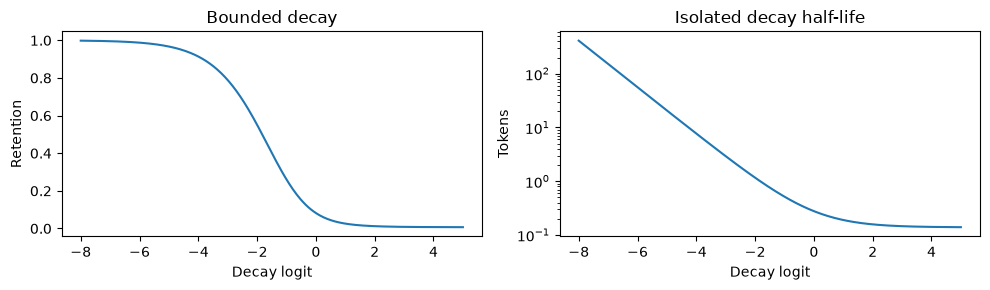

In [14]:
z = torch.linspace(-8, 5, 300)
retention = torch.exp(-5 * torch.sigmoid(z))
half_life = math.log(0.5) / retention.log()
fig, axes = plt.subplots(1, 2, figsize=(10, 3))
axes[0].plot(z, retention); axes[0].set(xlabel='Decay logit', ylabel='Retention', title='Bounded decay')
axes[1].semilogy(z, half_life); axes[1].set(xlabel='Decay logit', ylabel='Tokens', title='Isolated decay half-life')
fig.tight_layout(); plt.show()

## 15. Preserve global lookup with compressed KV attention

Fixed-size recurrent memory is lossy. A complementary global layer retains one latent vector per past token and performs softmax lookup. Let $c_t=W_cx_t\in\mathbb R^R$, $k_t=W_kc_t$, and $v_t=W_vc_t$. Only $c_t$ must persist between calls; keys and values can be reconstructed. Our tiny layer uses a direct query projection and explicit reconstruction, so it demonstrates the factorization without optimized weight absorption.

For a chunk with $P$ cached tokens, query index $i$ may attend to source index $j$ iff $j\leq P+i$. Using an unshifted triangular mask during cached decoding would hide valid history. A one-token call should see all cached tokens plus itself.

The output is gated before projecting back to residual width. We use NoPE, matching the report's global-attention choice: the surrounding recurrent layers provide order-sensitive representations. This does not mean the whole network is permutation invariant.

With left padding, causal masking alone is insufficient: a valid query must also exclude padded keys from softmax. We store a Boolean validity mask beside cached latents. A padded query is allowed to see earlier padded positions only to avoid an all-$-\infty$ softmax row; its output is then set to zero. Future positions remain blocked in either case. This keeps the valid suffix numerically equivalent to an unpadded sequence.

**Shapes:** latent cache $[B,P,R]$, cache validity $[B,P]$, attention scores $[B,H,T,P+T]$. **Inspect:** a split prefill/decode pass matches a full pass, and the padded valid suffix matches an unpadded call. Persistent cache is compressed, although reconstruction creates temporary memory.

In [15]:
class TinyGatedMLA(nn.Module):
    def __init__(self, c):
        super().__init__()
        self.h, self.d = c.heads, c.head_dim
        size = self.h * self.d
        self.down = nn.Linear(c.width, c.kv_rank, bias=False)
        self.latent_norm = RMSNorm(c.kv_rank)
        self.kv = nn.Linear(c.kv_rank, 2 * size, bias=False)
        self.query = nn.Linear(c.width, size, bias=False)
        self.gate = nn.Linear(c.width, size, bias=False)
        self.out = nn.Linear(size, c.width, bias=False)
    def forward(self, x, cache=None, valid_mask=None):
        b, t, _ = x.shape
        if valid_mask is None:
            valid_mask = torch.ones(b, t, dtype=torch.bool, device=x.device)
        current = self.latent_norm(self.down(x))
        past = 0 if cache is None else cache['latent'].shape[1]
        latent = current if cache is None else torch.cat([cache['latent'], current], dim=1)
        key_valid = valid_mask if cache is None else torch.cat([cache['valid'], valid_mask], dim=1)
        total = latent.shape[1]
        k, v = self.kv(latent).chunk(2, dim=-1)
        k = k.reshape(b, total, self.h, self.d).transpose(1, 2)
        v = v.reshape(b, total, self.h, self.d).transpose(1, 2)
        q = self.query(x).reshape(b, t, self.h, self.d).transpose(1, 2)
        scores = q @ k.transpose(-2, -1) / math.sqrt(self.d)
        causal = torch.arange(total, device=x.device)[None, :] <= past + torch.arange(t, device=x.device)[:, None]
        # Padded queries may see a causal prefix; they are zeroed after attention.
        allowed = causal[None, :, :] & (key_valid[:, None, :] | ~valid_mask[:, :, None])
        weights = scores.masked_fill(~allowed[:, None, :, :], -torch.inf).softmax(-1)
        y = (weights @ v).transpose(1, 2).reshape(b, t, -1)
        y = self.out(y * torch.sigmoid(self.gate(x))) * valid_mask[..., None]
        return y, {'latent': latent, 'valid': key_valid}

mla = TinyGatedMLA(cfg).eval()
x = torch.randn(2, 9, cfg.width)
with torch.no_grad():
    all_out, _ = mla(x)
    first, lc = mla(x[:, :5]); last, lc = mla(x[:, 5:], lc)
torch.testing.assert_close(all_out, torch.cat([first, last], 1), atol=1e-6, rtol=1e-5)
assert lc['latent'].shape == (2, 9, cfg.kv_rank)
assert lc['valid'].all()
short = torch.randn(1, 5, cfg.width)
padded = torch.cat([torch.zeros(1, 4, cfg.width), short], dim=1)
mask = torch.tensor([[False] * 4 + [True] * 5])
with torch.no_grad():
    plain, _ = mla(short)
    left_padded, _ = mla(padded, valid_mask=mask)
torch.testing.assert_close(plain, left_padded[:, -5:], atol=1e-6, rtol=1e-5)
print('Latent-cache shape:', tuple(lc['latent'].shape), '; cached and padding masks passed.')

Latent-cache shape: (2, 9, 12) ; cached and padding masks passed.


## 16. Quantify persistent memory separately from compute

For a single sequence, ordinary multi-head KV storage has $2THK$ scalars when key and value widths both equal $K$. A compressed latent cache has $TR$ scalars in this simplified NoPE design. One KDA state has $HK^2$ scalars, plus three convolution histories of $HK(w-1)$ scalars each.

These are **persistent inference-state formulas**, excluding parameters, activations, temporary reconstructed KV tensors, allocator overhead, and batching. A hybrid model still has growing MLA caches and global-attention compute. Thus a constant-size KDA state does not make the complete architecture constant-memory or linear-time in every regime.

**Inspect:** memory in MiB for illustrative widths. This is arithmetic accounting, not a hardware benchmark or an estimate of the complete official deployment footprint.

In [16]:
lengths = [128, 1024, 8192, 65536]
h, d, rank, window, bytes_per_scalar = 8, 64, 128, 4, 4
print(f'{"Tokens":>8} {"MHA KV MiB":>14} {"Latent MiB":>14} {"KDA MiB":>14}')
for t in lengths:
    mha = 2 * t * h * d
    latent = t * rank
    recurrent = h * d * d + 3 * h * d * (window - 1)
    mib = lambda n: n * bytes_per_scalar / 2**20
    print(f'{t:8d} {mib(mha):14.3f} {mib(latent):14.3f} {mib(recurrent):14.3f}')

  Tokens     MHA KV MiB     Latent MiB        KDA MiB
     128          0.500          0.062          0.143
    1024          4.000          0.500          0.143
    8192         32.000          4.000          0.143
   65536        256.000         32.000          0.143


## 17. Attend over depth: Attention Residuals

Ordinary residual addition accumulates sublayer outputs with fixed coefficients. Depth attention instead chooses a weighted mixture of earlier sources. For sources $v_i\in\mathbb R^D$ at one token position and a learned pseudo-query $w$, define
$$s_i=w^\top\operatorname{RMSNorm}(v_i),\quad a_i=\frac{e^{s_i}}{\sum_j e^{s_j}},\quad h=\sum_i a_i v_i.$$
The source axis is network **depth**, not sequence position. Keys are normalized but values remain unnormalized, preserving their scale. The query is learned per receiving sublayer; input dependence comes from the source representations. Zero query initialization gives a uniform average, not an unnormalized sum.

Reference: [Attention Residuals](https://github.com/MoonshotAI/Attention-Residuals). For the tiny implementation, we use a learned RMS gain in the key normalizer. There is no $1/\sqrt D$ factor in the score definition above.

**Shapes:** stacking $N$ sources produces $[N,B,T,D]$; weights are $[N,B,T]$ and sum to one over $N$. **Inspect:** initial output equals the mean and the query receives gradients.

In [17]:
class DepthAttention(nn.Module):
    def __init__(self, width):
        super().__init__()
        self.query = nn.Parameter(torch.zeros(width))
        self.key_norm = RMSNorm(width)
    def forward(self, sources):
        values = torch.stack(sources, dim=0)
        scores = torch.einsum('nbtd,d->nbt', self.key_norm(values), self.query)
        weights = scores.softmax(dim=0)
        return (weights[..., None] * values).sum(dim=0)

sources = [torch.randn(2, 5, cfg.width) for _ in range(3)]
depth = DepthAttention(cfg.width)
mixed = depth(sources)
torch.testing.assert_close(mixed, torch.stack(sources).mean(0))
mixed.square().mean().backward()
assert depth.query.grad is not None and depth.query.grad.norm() > 0
print('Depth averaging and pseudo-query gradient checks passed.')

Depth averaging and pseudo-query gradient checks passed.


## 18. Block depth memory without double-counting residuals

Keeping every sublayer output as a separate source grows activation storage with depth. We group consecutive sublayer outputs into partial sums. Completed block sums and the original embedding stay available; the current unfinished sum is included only after at least one output has been added.

If $u_1,u_2$ are outputs in one block, store $b=u_1+u_2$, not $(x+u_1)+(x+u_1+u_2)$. The latter double-counts previous content. The receiving sublayer computes $u=f(\operatorname{Norm}(\operatorname{DepthAttention}(sources)))$; we append this **new output**, not an ordinary residual-updated hidden state. Final depth attention reads completed blocks and any remaining partial block.

Our block size counts attention and feed-forward **sublayers**, an explicitly educational grouping. We do not claim to reproduce K3's production block boundaries.

**Inspect:** two outputs become one sum, the third remains a partial block, and embedding remains a separate source. This helper is per-forward-pass depth memory, not a temporal KV cache.

In [18]:
class DepthBank:
    def __init__(self, embedding, block_size):
        self.completed = [embedding]
        self.partial = None
        self.count = 0
        self.block_size = block_size
    def sources(self):
        return self.completed + ([] if self.partial is None else [self.partial])
    def append(self, output):
        self.partial = output if self.partial is None else self.partial + output
        self.count += 1
        if self.count == self.block_size:
            self.completed.append(self.partial)
            self.partial, self.count = None, 0

embedding = torch.randn(1, 2, cfg.width)
u = [torch.randn_like(embedding) for _ in range(3)]
bank = DepthBank(embedding, 2)
for item in u: bank.append(item)
assert len(bank.sources()) == 3
torch.testing.assert_close(bank.sources()[1], u[0] + u[1])
torch.testing.assert_close(bank.sources()[2], u[2])
print('Block depth-memory bookkeeping passed.')

Block depth-memory bookkeeping passed.


## 19. Build a bounded gated expert

A gated feed-forward expert multiplies two projected branches and maps them back to the input width. We use SiTU-GLU with gate projection $g=W_gx$ and up projection $u=W_ux$:
$$f(x)=W_d\left([4\tanh(g/4)\odot\sigma(g)]\odot[25\tanh(u/25)]\right).$$
The activation definition is from [K3, equation 12](https://arxiv.org/html/2607.24653v1#S2.SS3). To understand it, expand $c\tanh(x/c)=x-x^3/(3c^2)+\cdots$: near zero it resembles the original linear factor. At large magnitude it approaches a smooth cap. Since $|\tanh|\leq1$ and $0\leq\sigma\leq1$, the intermediate product has absolute value at most $100$.

This does **not** bound the final expert output by $100$: the down-projection can amplify it. Bounded activations also do not guarantee bounded gradients for the entire network.

**Shapes:** input $[...,d]$, two branches $[...,m]$, output $[...,d]$. **Inspect:** the product stays bounded even for large inputs; the final layer preserves shape.

In [19]:
def situ_product(g, u):
    return (4 * torch.tanh(g / 4) * torch.sigmoid(g)) * (25 * torch.tanh(u / 25))

class Expert(nn.Module):
    def __init__(self, width, hidden):
        super().__init__()
        self.gate = nn.Linear(width, hidden, bias=False)
        self.up = nn.Linear(width, hidden, bias=False)
        self.down = nn.Linear(hidden, width, bias=False)
    def forward(self, x):
        return self.down(situ_product(self.gate(x), self.up(x)))

large = torch.linspace(-1000, 1000, 10000)
assert situ_product(large, large).abs().max() <= 100 + 1e-5
expert = Expert(cfg.width, cfg.expert_hidden)
assert expert(torch.randn(2, 5, cfg.width)).shape == (2, 5, cfg.width)
print('Intermediate activation bound:', situ_product(large, large).abs().max().item())

Intermediate activation bound: 100.0


## 20. Top-k routing: separate selection from mixing

A router scores experts using $s=\sigma(W_rx)$. Select the largest $k$ entries of $s+b$, where $b$ is a non-gradient balancing bias. For the selected set $\mathcal T$, mixture weights are
$$p_j=\frac{s_j}{\sum_{r\in\mathcal T}s_r},\qquad j\in\mathcal T.$$
The bias influences **which** experts are selected, while the unmodified scores determine **how much** each selected expert contributes. This distinction prevents the balancing controller from directly rescaling mixtures. Top-k indices are discrete; gradients propagate through selected score values and expert computations, not through changes in the selected set.

**Shapes:** scores $[N,E]$, selected indices and weights $[N,k]$, where $N=BT$. **Inspect:** exactly $Nk$ assignments exist, weights sum to one per token, and a large selection bias can choose an expert without replacing its underlying score.

> **Interview insight:** Sparse activation reduces executed expert work, but all expert weights still need storage somewhere. Active parameters and total parameters answer different resource questions.

In [20]:
def route(scores, bias, top_k):
    selected = (scores + bias).topk(top_k, dim=-1).indices
    weights = scores.gather(-1, selected)
    weights = weights / weights.sum(-1, keepdim=True).clamp_min(1e-9)
    return selected, weights

scores = torch.tensor([[0.9, 0.8, 0.2, 0.1], [0.2, 0.1, 0.8, 0.9]])
bias = torch.tensor([0., 0., 0., 2.])
selected, weights = route(scores, bias, 2)
torch.testing.assert_close(weights.sum(-1), torch.ones(2))
assert (selected[:, 0] == 3).all()
print('Selected experts:', selected.tolist())
print('Unbiased normalized weights:', weights.tolist())

Selected experts: [[3, 0], [3, 2]]
Unbiased normalized weights: [[0.10000000149011612, 0.8999999761581421], [0.5294117331504822, 0.47058823704719543]]


## 21. Build the latent MoE with actual sparse dispatch

Full-width shared experts process every token. Routed experts process a compressed representation $z=W_{\downarrow}x\in\mathbb R^\ell$. Selected outputs are combined in latent space, normalized, and projected back:
$$u=\sum_{j\in\mathcal T}p_jE_j(z),\quad y=\sum_aE_a^{shared}(x)+W_{\uparrow}\operatorname{RMSNorm}(u).$$
The two projection matrices separate residual width from expert width. This saves expert parameters when $\ell<D$, at the cost of a bottleneck. A full-width shared path can represent transformations useful to all tokens. The implementation gathers only tokens assigned to each expert; computing every expert and then masking would not demonstrate sparse execution.

We record detached routing statistics only for **real tokens** in training mode for a later balancing update. Padded positions do not dispatch experts or contribute to load counts. Forward does not mutate the bias. This keeps evaluation deterministic and prevents a token's routing from depending on future tokens through a same-batch update.

**Shapes:** flattened input $[BT,D]$, latent $[BT,\ell]$, routed accumulation $[BT,\ell]$, output $[B,T,D]$. If $N$ positions are real, the assignment count is $Nk$. **Inspect:** output shape and assignment counts. Python dispatch loops prioritize readability, not speed.

In [21]:
class LatentMoE(nn.Module):
    def __init__(self, c):
        super().__init__()
        self.top_k, self.n_experts = c.top_k, c.experts
        self.router = nn.Linear(c.width, c.experts, bias=False)
        self.register_buffer('bias', torch.zeros(c.experts))
        self.down = nn.Linear(c.width, c.latent, bias=False)
        self.up = nn.Linear(c.latent, c.width, bias=False)
        self.norm = RMSNorm(c.latent)
        self.routed = nn.ModuleList([Expert(c.latent, c.expert_hidden) for _ in range(c.experts)])
        self.shared = nn.ModuleList([Expert(c.width, c.expert_hidden) for _ in range(c.shared)])
        self.pending_scores = None
        self.last_counts = None
    def forward(self, x, valid_mask=None):
        shape = x.shape
        if valid_mask is None:
            valid_mask = torch.ones(shape[:-1], dtype=torch.bool, device=x.device)
        flat_valid = valid_mask.reshape(-1)
        flat = x.reshape(-1, shape[-1])
        scores = torch.sigmoid(self.router(flat))
        indices, weights = route(scores, self.bias, self.top_k)
        z = self.down(flat)
        acc = torch.zeros_like(z)
        for e, expert in enumerate(self.routed):
            token_ids, slots = torch.where((indices == e) & flat_valid[:, None])
            if token_ids.numel():
                contribution = expert(z[token_ids]) * weights[token_ids, slots, None]
                acc = acc.index_add(0, token_ids, contribution)
        shared = sum(expert(flat) for expert in self.shared)
        result = (shared + self.up(self.norm(acc))) * flat_valid[:, None]
        if self.training:
            self.pending_scores = scores[flat_valid].detach()
            self.last_counts = torch.bincount(indices[flat_valid].flatten(), minlength=self.n_experts).detach()
        return result.reshape(shape)

moe = LatentMoE(cfg)
y = moe(torch.randn(2, 7, cfg.width))
assert y.shape == (2, 7, cfg.width)
assert moe.last_counts.sum().item() == 2 * 7 * cfg.top_k
print('Expert assignment counts:', moe.last_counts.tolist())

Expert assignment counts: [11, 4, 9, 4]


## 22. Quantile balancing as a delayed controller

Overused experts become bottlenecks and unused experts receive little learning signal. K3's quantile rule uses the $(k+1)$-th biased score as each token's cutoff, forms raw-score margins, and computes a new per-expert quantile bias. It applies the update on the next step and freezes it for inference ([equations 13–14](https://arxiv.org/html/2607.24653v1#S2.SS3)).

For our local exercise, $a_i=\operatorname{top}_{k+1}(s_i+b)$ denotes that cutoff and
$$\widehat b_j=-\operatorname{quantile}_{1-k/E}(s_{:,j}-a),\qquad b'_j=\widehat b_j-\operatorname{mean}(\widehat b).$$
Subtracting a common mean does not change top-k ordering. Quantiles estimate a threshold for a desired fraction of assignments. Since competing experts and cutoffs also change, exact balance is not guaranteed on every next batch. Ties, small batches, and interpolation further affect discrete counts. We use PyTorch's linear-interpolated quantile as a transparent local approximation, not the distributed production estimator.

**Inspect:** the new bias is finite and centered; a forward pass alone leaves bias unchanged. Evaluation and generation never run this update.

In [22]:
@torch.no_grad()
def quantile_bias(scores, old_bias, top_k):
    cutoff = (scores + old_bias).topk(top_k + 1, dim=-1).values[:, -1:]
    margins = scores - cutoff
    new_bias = -torch.quantile(margins.float(), 1 - top_k / scores.shape[-1], dim=0)
    return new_bias - new_bias.mean()

@torch.no_grad()
def update_router_biases(model):
    for module in model.modules():
        if isinstance(module, LatentMoE) and module.pending_scores is not None:
            module.bias.copy_(quantile_bias(module.pending_scores, module.bias, module.top_k))
            module.pending_scores = None

before = moe.bias.clone()
_ = moe(torch.randn(2, 7, cfg.width))
torch.testing.assert_close(before, moe.bias)
update_router_biases(moe)
assert torch.isfinite(moe.bias).all()
assert abs(moe.bias.mean().item()) < 1e-6
print('Centered next-step bias:', moe.bias.tolist())

Centered next-step bias: [0.03908103331923485, -0.06795403361320496, 0.03746252879500389, -0.008589524775743484]


## 23. Assemble the complete autoregressive decoder

We now connect the components without hiding them behind a pretrained-model library. Token embeddings supply the initial depth source. The PAD lookup is multiplied by a validity mask, so the left prefix is exactly zero even when the embedding matrix is tied to the output head and its PAD row receives output-class gradients. Before every token mixer and feature mixer, its own DepthAttention module retrieves a representation, followed by RMSNorm. New outputs are appended to the depth bank. A final depth read produces vocabulary logits.

The first feature mixer is dense; later mixers use latent MoE. Attention modules each maintain their own temporal cache; global-attention caches also retain per-position validity masks. The depth bank is rebuilt for the current input chunk, while temporal caches persist across chunks. These are different axes of memory and should not share a data structure.

Our output head is tied to the embedding matrix: $z_t=h_tE^\top$. This educational choice reduces parameter count and is not a claim about official weight tying. Small normal initialization keeps initial logits moderate. There is no positional embedding, dropout, or external model download.

**Shapes:** tokens $[B,T]$ become embeddings $[B,T,D]$, then logits $[B,T,V]$. **Inspect:** trainable parameter count and finite logits. The returned cache has one entry for each token-mixing layer.

In [23]:
class TinyK3(nn.Module):
    def __init__(self, c):
        super().__init__()
        self.config = c
        self.embedding = nn.Embedding(c.vocab, c.width)
        self.mixers = nn.ModuleList([TinyKDA(c) if kind == 'kda' else TinyGatedMLA(c) for kind in c.schedule])
        self.ffns = nn.ModuleList([Expert(c.width, c.expert_hidden) if i == 0 else LatentMoE(c) for i in range(len(c.schedule))])
        self.depth_reads = nn.ModuleList([DepthAttention(c.width) for _ in range(2 * len(c.schedule))])
        self.norms = nn.ModuleList([RMSNorm(c.width) for _ in range(2 * len(c.schedule))])
        self.final_depth = DepthAttention(c.width)
        self.final_norm = RMSNorm(c.width)
        self.apply(self._init)
    @staticmethod
    def _init(module):
        if isinstance(module, (nn.Linear, nn.Embedding)):
            nn.init.normal_(module.weight, std=0.04)
    def forward(self, token_ids, caches=None):
        valid_mask = token_ids != self.config.pad_id
        bank = DepthBank(self.embedding(token_ids) * valid_mask[..., None], self.config.block_sublayers)
        if caches is None: caches = [None] * len(self.mixers)
        if len(caches) != len(self.mixers): raise ValueError('Cache layer count mismatch')
        new_caches = []
        for i, (mixer, ffn) in enumerate(zip(self.mixers, self.ffns)):
            h = self.norms[2*i](self.depth_reads[2*i](bank.sources()))
            if isinstance(mixer, TinyGatedMLA):
                update, cache = mixer(h, caches[i], valid_mask)
            else:
                update, cache = mixer(h, caches[i])
            update = update * valid_mask[..., None]
            bank.append(update); new_caches.append(cache)
            h = self.norms[2*i+1](self.depth_reads[2*i+1](bank.sources()))
            ff = ffn(h, valid_mask) if isinstance(ffn, LatentMoE) else ffn(h)
            bank.append(ff * valid_mask[..., None])
        h = self.final_norm(self.final_depth(bank.sources()))
        logits = F.linear(h, self.embedding.weight)
        return logits, new_caches

torch.manual_seed(SEED)
model = TinyK3(cfg).to(DEVICE)
logits, _ = model(xb)
assert logits.shape == (BATCH, SEQ, V) and torch.isfinite(logits).all()
for module in model.modules():
    if isinstance(module, LatentMoE):
        assert module.last_counts.sum().item() == int((xb != PAD_ID).sum()) * cfg.top_k
print('Integrated routing counts only real tokens.')
print('Parameters:', f'{sum(p.numel() for p in model.parameters()):,}')
print('Logits:', tuple(logits.shape))

Integrated routing counts only real tokens.
Parameters: 73,198
Logits: (8, 16, 30)


## 24. Test causality, left-padding invariance, and cached decoding

Module checks are not enough: test the whole decoder. First, changing future input tokens must not alter earlier logits. Next, the valid suffix of a left-padded input must match the same sequence supplied without padding. This verifies that padded embeddings stay zero, recurrent state starts at zero, causal convolution receives equivalent left context, global attention excludes padded keys, and depth mixing does not leak padding.

Finally, compare a full pass with a prefill chunk followed by one-token calls using caches. The global cache now carries both latent vectors and validity flags. In evaluation mode, routing biases are frozen. We compare logits only at real positions for semantic padding invariance; padded-query logits are irrelevant to the loss.

**Inspect:** maximum numerical discrepancies, not merely pass/fail. These checks establish internal consistency of the educational model, not parity with official K3 weights.

In [24]:
model.eval()
with torch.no_grad():
    probe = xb[:2]
    base, _ = model(probe)
    changed = probe.clone(); changed[:, 10:] = (changed[:, 10:] + 3) % PAD_ID
    perturbed, _ = model(changed)
    torch.testing.assert_close(base[:, :10], perturbed[:, :10], atol=2e-5, rtol=2e-5)
    first, caches = model(probe[:, :7])
    parts = [first]
    for t in range(7, probe.shape[1]):
        piece, caches = model(probe[:, t:t+1], caches); parts.append(piece)
    cached = torch.cat(parts, 1)
    torch.testing.assert_close(base, cached, atol=3e-5, rtol=3e-5)
    short = encode('the robot')[None, :]
    padded = F.pad(short, (7, 0), value=PAD_ID)
    plain_logits, _ = model(short)
    padded_logits, _ = model(padded)
    torch.testing.assert_close(plain_logits, padded_logits[:, -short.shape[1]:], atol=3e-5, rtol=3e-5)
print('Future-perturbation error:', (base[:, :10] - perturbed[:, :10]).abs().max().item())
print('Cached decoding error:', (base - cached).abs().max().item())
print('Left-padding invariance error:', (plain_logits - padded_logits[:, -short.shape[1]:]).abs().max().item())

Future-perturbation error: 1.1920928955078125e-07
Cached decoding error: 8.977949619293213e-07
Left-padding invariance error: 3.501772880554199e-07


## 25. Audit gradients before spending time training

A differentiable implementation can run forward while silently disconnecting a branch. Compute the language-model loss, call backward, and inspect gradients for the embedding, KDA projection, depth pseudo-query, router, and an expert actually selected in this batch. Nonselected experts may correctly have no gradient for a given batch.

We also compare sparse MoE output with a slow dense reference that computes every expert. This validates token dispatch and weighted accumulation independently of the fast path's indexing. The dense reference is used only for verification, never as the training implementation.

**Inspect:** all observed gradient norms are finite and positive, and sparse/dense outputs agree. Clear gradients afterwards so this diagnostic batch is not accidentally accumulated into the first optimizer step.

In [25]:
model.train(); model.zero_grad(set_to_none=True)
logits, _ = model(xb)
loss = masked_loss(logits, yb)
loss.backward()
checks = {
    'embedding': model.embedding.weight,
    'KDA QKV': model.mixers[0].qkv.weight,
    'depth query': model.depth_reads[2].query,
    'router': model.ffns[1].router.weight,
}
chosen = int(model.ffns[1].last_counts.argmax())
checks['selected expert'] = model.ffns[1].routed[chosen].down.weight
for name, parameter in checks.items():
    assert parameter.grad is not None and torch.isfinite(parameter.grad).all()
    assert parameter.grad.norm() > 0
    print(name, 'gradient norm:', round(parameter.grad.norm().item(), 6))

m = model.ffns[1]
x = torch.randn(2, 4, cfg.width)
with torch.no_grad():
    sparse = m(x)
    flat = x.reshape(-1, cfg.width)
    scores = m.router(flat).sigmoid()
    ids, weights = route(scores, m.bias, m.top_k)
    all_outputs = torch.stack([e(m.down(flat)) for e in m.routed], dim=1)
    selected_outputs = all_outputs[torch.arange(flat.shape[0])[:, None], ids]
    acc = (selected_outputs * weights[..., None]).sum(1)
    dense = sum(e(flat) for e in m.shared) + m.up(m.norm(acc))
    torch.testing.assert_close(sparse, dense.reshape_as(sparse), atol=1e-6, rtol=1e-5)
model.zero_grad(set_to_none=True)
for m in model.modules():
    if isinstance(m, LatentMoE): m.pending_scores = None
print('Sparse dispatch agrees with dense reference.')

embedding gradient norm: 3.801187
KDA QKV gradient norm: 3.868156
depth query gradient norm: 0.168952
router gradient norm: 0.006727
selected expert gradient norm: 0.048415
Sparse dispatch agrees with dense reference.


## 26. Fix the evaluation protocol

Validation should not change router bias, parameters, optimizer state, or subsequent training-data draws. We construct fixed evaluation batches with a separate generator. Variable-length batches contain different numbers of real targets. We therefore sum their losses and divide by the total number of non-PAD targets across all evaluation batches.

Training and validation documents share a small grammar but are disjoint full strings. Window overlap at the substring level is expected for this task. The resulting validation loss is a diagnostic of the training pipeline, not a benchmark. We also hold out fixed training batches to distinguish optimization progress from a lucky random minibatch.

**Inspect:** initial train and validation losses near the uniform baseline. Exact values depend on initialization. The helper restores the model's previous train/eval mode and runs without gradients.

In [26]:
eval_rng = torch.Generator().manual_seed(901)
fixed_train = [get_batch(train_tokens, generator=eval_rng) for _ in range(4)]
fixed_val = [get_batch(val_tokens, generator=eval_rng) for _ in range(4)]

@torch.no_grad()
def evaluate(model, batches):
    was_training = model.training
    model.eval()
    total_loss, total_tokens = 0.0, 0
    for inputs, targets in batches:
        logits, _ = model(inputs)
        total_loss += masked_loss(logits, targets, reduction='sum').item()
        total_tokens += int((targets != PAD_ID).sum())
    model.train(was_training)
    return total_loss / total_tokens

initial_train = evaluate(model, fixed_train)
initial_val = evaluate(model, fixed_val)
print(f'Initial train: {initial_train:.4f}; validation: {initial_val:.4f}; uniform: {math.log(V):.4f}')

Initial train: 3.4482; validation: 3.4429; uniform: 3.4012


## 27. Train with AdamW, clipping, and a small learning-rate schedule

For each batch, compute loss, differentiate, clip the total gradient norm, and update parameters. Global-norm clipping replaces $g$ by $g\min(1,c/\|g\|_2)$; it limits the update input but does not repair an invalid forward pass. AdamW maintains moving first and second moments and decouples weight decay from the gradient-based update.

We warm up linearly for a few steps, then decay the learning rate with a cosine. The quantile controller reads detached scores from the just-completed batch and sets biases for the **next** batch. No temporal cache is carried across independent training documents. This local tutorial uses one batch per step; gradient accumulation would require collecting routing statistics across all microbatches before balancing.

The official training recipe is far larger and uses different optimization infrastructure. This run only demonstrates that the assembled decoder can learn next-token structure. Default: 120 steps, eight sequences per batch, and between six and sixteen real predictions per sequence. PAD positions make no contribution to the loss or router load statistics. Sequential recurrence can take a few minutes on a CPU.

**Inspect:** finite loss, bounded gradients after clipping, and decreasing held-out training loss. Validation may fluctuate; a toy run is not evidence for architecture superiority.

In [27]:
STEPS = 120
optimizer = torch.optim.AdamW(model.parameters(), lr=3e-3, weight_decay=0.01)
history = [{'step': 0, 'train': initial_train, 'val': initial_val}]
start_time = time.perf_counter()
model.train()
for step_id in range(1, STEPS + 1):
    warmup = 10
    if step_id <= warmup:
        factor = step_id / warmup
    else:
        progress = (step_id - warmup) / (STEPS - warmup)
        factor = 0.1 + 0.9 * 0.5 * (1 + math.cos(math.pi * progress))
    for group in optimizer.param_groups: group['lr'] = 3e-3 * factor
    inputs, targets = get_batch(train_tokens)
    optimizer.zero_grad(set_to_none=True)
    logits, _ = model(inputs)
    loss = masked_loss(logits, targets)
    if not torch.isfinite(loss): raise RuntimeError('Non-finite training loss')
    loss.backward()
    grad_norm = torch.nn.utils.clip_grad_norm_(model.parameters(), 1.0, error_if_nonfinite=True)
    optimizer.step()
    update_router_biases(model)
    if step_id % 20 == 0:
        record = {'step': step_id, 'train': evaluate(model, fixed_train), 'val': evaluate(model, fixed_val)}
        history.append(record)
        print(f"step {step_id:3d} | train {record['train']:.4f} | val {record['val']:.4f} | pre-clip norm {grad_norm:.3f}")
last_valid_tokens = int((inputs != PAD_ID).sum())
training_seconds = time.perf_counter() - start_time
assert history[-1]['train'] < initial_train, 'Investigate learning rate, labels, and gradients.'
print(f'Training time: {training_seconds:.1f}s')

step  20 | train 2.7610 | val 2.7766 | pre-clip norm 4.466


step  40 | train 2.1120 | val 2.0911 | pre-clip norm 2.456


step  60 | train 1.6580 | val 1.6417 | pre-clip norm 3.894


step  80 | train 1.3056 | val 1.2535 | pre-clip norm 2.490


step 100 | train 1.1249 | val 1.0604 | pre-clip norm 1.766


step 120 | train 1.0434 | val 0.9885 | pre-clip norm 1.596
Training time: 5.0s


## 28. Read the learning curve and expert loads

Plot the fixed train and validation losses against optimizer steps. A decreasing training curve establishes that the optimizer can fit structure. A growing train/validation gap can indicate overfitting, but this tiny dataset and short run cannot support strong statistical conclusions.

Expert counts show the final training batch, not a global average. If $N$ tokens are real in the final batch, there are $Nk$ assignments per MoE layer, so the ideal uniform count is $Nk/E$. This is a useful reference line, not a hard constraint enforced by our quantile controller. Different experts can legitimately specialize; balanced counts alone do not establish useful specialization.

**Inspect:** actual saved measurements, with axes and baseline labeled. The plots are generated from this execution rather than illustrative fabricated curves.

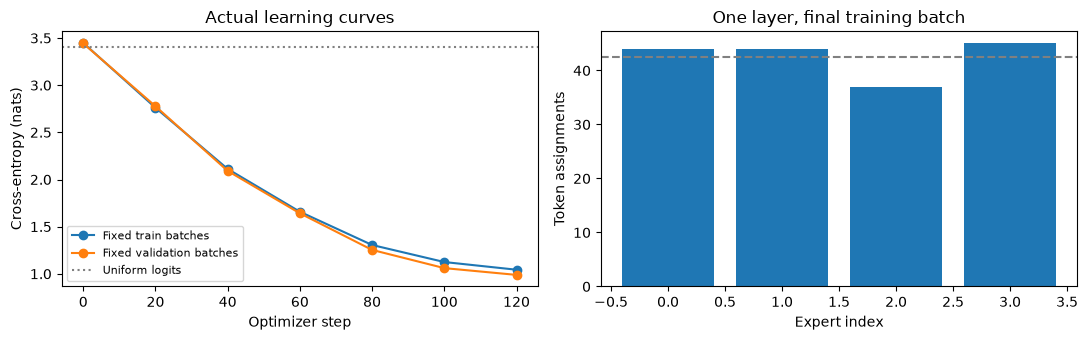

Final validation perplexity: 2.687


In [28]:
fig, axes = plt.subplots(1, 2, figsize=(11, 3.5))
axes[0].plot([r['step'] for r in history], [r['train'] for r in history], 'o-', label='Fixed train batches')
axes[0].plot([r['step'] for r in history], [r['val'] for r in history], 'o-', label='Fixed validation batches')
axes[0].axhline(math.log(V), color='gray', linestyle=':', label='Uniform logits')
axes[0].set(xlabel='Optimizer step', ylabel='Cross-entropy (nats)', title='Actual learning curves')
axes[0].legend(fontsize=8)
counts = model.ffns[1].last_counts.cpu()
axes[1].bar(range(cfg.experts), counts)
axes[1].axhline(last_valid_tokens * cfg.top_k / cfg.experts, color='gray', linestyle='--')
axes[1].set(xlabel='Expert index', ylabel='Token assignments', title='One layer, final training batch')
fig.tight_layout(); plt.show()
print('Final validation perplexity:', round(math.exp(history[-1]['val']), 3))

## 29. Generate using prefill and cached one-token decoding

Prefill processes the entire prompt once and initializes caches. The last real prompt logit predicts the first new token. The PAD vocabulary ID is masked before sampling, because it is a batching device rather than a character. After sampling that token, feed **only that token** with the previous caches to predict the next one. Refeeding the whole prompt while reusing its cache would duplicate history.

Temperature rescales logits as $z/\tau$ before softmax. Smaller positive $\tau$ makes sampling more concentrated; $\tau=0$ is handled separately as greedy argmax. Optional top-k sampling removes all but the highest k logits and renormalizes. This sampling top-k is unrelated to MoE expert top-k.

**Inspect:** generated text and cached-vs-full agreement after training. The tiny model is expected to learn fragments of the synthetic grammar, not answer questions or reason. Cache growth is unbounded in this short demo's global layers; production serving needs explicit context and memory limits.

In [29]:
@torch.no_grad()
def generate(model, prompt, max_new_tokens=64, temperature=0.7, top_k=8):
    if not prompt: raise ValueError('Provide at least one prompt character.')
    if temperature < 0: raise ValueError('Temperature must be nonnegative.')
    model.eval()
    tokens = encode(prompt)[None, :].to(DEVICE)
    logits, caches = model(tokens)
    generated = [tokens]
    for _ in range(max_new_tokens):
        scores = logits[:, -1].clone()
        scores[:, PAD_ID] = -torch.inf
        if temperature == 0:
            nxt = scores.argmax(-1, keepdim=True)
        else:
            scores = scores / temperature
            if top_k is not None:
                if top_k < 1: raise ValueError('top_k must be positive.')
                values, indices = scores.topk(min(top_k, scores.shape[-1]), dim=-1)
                filtered = torch.full_like(scores, -torch.inf)
                scores = filtered.scatter(-1, indices, values)
            nxt = torch.multinomial(scores.softmax(-1), 1)
        generated.append(nxt)
        logits, caches = model(nxt, caches)
    return decode(torch.cat(generated, dim=1)[0])

torch.manual_seed(SEED)
print(generate(model, 'the ', max_new_tokens=80))
with torch.no_grad():
    full, _ = model(xb[:1, :10])
    prefix, cache = model(xb[:1, :9])
    last, _ = model(xb[:1, 9:10], cache)
    torch.testing.assert_close(full[:, -1:], last, atol=5e-5, rtol=5e-5)
print('Post-training cache equivalence passed.')

the teachecbs a b e s a theorylxeet rhtbook.
zlkdds a tooostt ae student tests a tls
Post-training cache equivalence passed.


## 30. Save and restore a portable tutorial checkpoint

Weights alone are insufficient for reliable reuse: restore the model dimensions and token mapping too. The checkpoint below stores the configuration, character vocabulary, state dictionary, loss history, and a scope label. Router biases are registered buffers, so they are included in the state dictionary even though the optimizer does not train them.

For a bitwise training resume, one would also need optimizer and scheduler state, all random-number-generator states, and data-loader position. This artifact is an **inference checkpoint**, not a full training-resume snapshot. The notebook writes it in an `artifacts` directory relative to its execution directory.

**Inspect:** a newly constructed model produces matching logits after loading. `weights_only=True` limits loading to supported tensor/basic-container data; load only checkpoints you intend to trust.

In [30]:
artifact_dir = Path('artifacts')
artifact_dir.mkdir(exist_ok=True)
checkpoint_path = artifact_dir / 'tiny_k3_educational.pt'
torch.save({'config': asdict(cfg), 'alphabet': alphabet, 'pad_id': PAD_ID, 'state_dict': model.state_dict(),
            'history': history, 'scope': 'K3-inspired educational model; not official weights'}, checkpoint_path)
loaded = torch.load(checkpoint_path, map_location=DEVICE, weights_only=True)
restored = TinyK3(Config(**loaded['config'])).to(DEVICE)
restored.load_state_dict(loaded['state_dict']); restored.eval(); model.eval()
assert loaded['alphabet'] == alphabet and loaded['pad_id'] == PAD_ID
with torch.no_grad():
    expected, _ = model(xb[:1]); actual, _ = restored(xb[:1])
torch.testing.assert_close(expected, actual)
print('Checkpoint:', checkpoint_path)
print('Reload equivalence passed.')

Checkpoint: artifacts/tiny_k3_educational.pt
Reload equivalence passed.


## 31. Optional interface exercise: image patches become prefix vectors

A multimodal decoder ultimately consumes vectors with the same residual width as text embeddings. To understand this boundary without pretending to reproduce a vision encoder, split an image of shape $[B,3,H,W]$ into non-overlapping $p\times p$ patches. Each flattened patch has $3p^2$ values. A linear map projects these into $D$ dimensions.

A convolution with kernel and stride both equal to $p$ implements this patch projection. The token count is $(H/p)(W/p)$. A real vision tower adds contextual processing, spatial information, preprocessing, and learned alignment. Our projection has none of those capabilities and is **not inserted into the trained text model**.

**Inspect:** image-prefix and text embeddings can be concatenated along the sequence axis. This is only a shape/interface exercise; no image-caption training occurs. If you later train a multimodal version, define positional structure and a loss mask that supervises text targets rather than inventing image-token class labels.

In [31]:
patch_size = 4
patch_projection = nn.Conv2d(3, cfg.width, kernel_size=patch_size, stride=patch_size, bias=False)
synthetic_image = torch.rand(1, 3, 16, 16)
image_prefix = patch_projection(synthetic_image).flatten(2).transpose(1, 2)
text_embeddings = model.embedding(encode('the robot')[None, :])
combined = torch.cat([image_prefix, text_embeddings], dim=1)
assert image_prefix.shape == (1, 16, cfg.width)
print('Image prefix:', tuple(image_prefix.shape))
print('Combined embedding interface:', tuple(combined.shape))

Image prefix: (1, 16, 32)
Combined embedding interface: (1, 25, 32)


## What the experiments establish—and their limits

The saved outputs demonstrate an executable teaching model, numerical consistency of its recurrent and cached paths, correct causal behavior, trainable routing and depth selection, and a working optimization loop. They do not establish official checkpoint parity, long-context quality, production speed, multimodal understanding, or any published benchmark result.

### Trade-offs

| Mechanism | Advantage | Cost or failure mode |
|---|---|---|
| Dense causal attention | Direct access to every retained token | Quadratic prefill comparisons; growing cache |
| KDA recurrence | Fixed-size temporal state per head | Compressed memory; sequential reference implementation is slow |
| Latent KV attention | Smaller persistent cache | Reconstruction work; global interaction still grows with context |
| Block depth attention | Selective use of earlier transformations | Additional reads and source storage; block boundaries matter |
| Sparse latent experts | More stored capacity per active computation | Routing discontinuities, load imbalance, dispatch overhead |
| Shared experts | Always available common transformations | Compute paid for every token |
| SiTU-GLU | Bounded intermediate products | Saturation can weaken gradients; projections remain unbounded |

### Common mistakes and debugging order

1. **Loss looks suspiciously good immediately:** check shifted labels, ignored PAD targets, and future leakage.
2. **Full pass works but decoding fails:** check convolution history, state order, and the cached causal-mask offset.
3. **MoE runs but does not save expert work:** inspect whether all experts are computed before masking.
4. **Validation changes model behavior:** ensure balancing updates happen only after training steps.
5. **Depth activations explode:** ensure you store new sublayer outputs, not repeatedly accumulated hidden states.
6. **Lower precision breaks recurrence:** first compare float32 against the explicit matrix reference; investigate underflow, saturation, and state dtype before changing equations.
7. **One million tokens fit in an API specification:** that is not evidence that this tiny model can retrieve information over that distance.
8. **Loss decreases but output looks odd:** a tiny character model may learn local transitions before complete grammar. Inspect held-out loss and greedy versus sampled output.

## Guided experiments

- **Memory:** force a constant retention of $0.5$, $0.9$, and $0.99$ in an isolated recurrence. Predict half-lives analytically, then measure the state norm with writes disabled. Keep the random seed fixed.
- **Routing:** use one expert, then four with top-2. Compare total parameters and executed assignments separately. Changing architecture requires training each variant from scratch.
- **Depth:** replace each depth read with a plain sum in a separate model. Match data, update count, and initialization policy; report multiple seeds before drawing conclusions.
- **Context:** increase the sequence window only after providing longer training documents. Compare memory formulas with measured peak allocation; persistent cache and peak memory are different quantities.
- **Balancing:** freeze zero router biases in a fresh training run. Compare assignment histograms and loss. Uniform dispatch is not automatically superior learning.
- **Faithful reproduction:** obtain a pinned official config and implementation, map every tensor, and compare layer outputs under identical weights. This notebook is a starting point for that work, not a substitute for it.

## Common interview questions

**1. Why can a causal attention mask include its diagonal?**
The token at position $t$ is an input used to predict token $t+1$. It is not the target itself. Label shifting and masking must be considered together.

**2. What makes the delta rule different from additive memory?**
It writes the residual error between a desired value and the value currently predicted from the key. With a unit key and write strength one, the current key-value association is exactly replaced along that key direction.

**3. Why does the order of decay and correction matter?**
A diagonal decay matrix and a key-dependent rank-one matrix generally do not commute. Swapping them changes both which state is read for the error and which directions are forgotten.

**4. Is linear attention constant-memory during training?**
Its recurrent inference state can be independent of context length, but backpropagation requires saved or recomputed intermediate information. Training memory depends on the chosen algorithm and checkpointing scheme.

**5. Why retain global layers in a recurrent model?**
Compressed recurrent state sacrifices direct access to arbitrary old token representations. Global layers provide another path for content-based retrieval while recurrent layers supply economical sequential mixing.

**6. Is MLA simply fewer attention heads?**
No. It factorizes key/value representations through a shared low-dimensional latent. It can retain multiple heads while changing the representation that must be cached.

**7. How can NoPE still encode order?**
The causal recurrence and local convolution depend on token order before global layers receive their inputs. Omitting an explicit positional embedding does not remove those order-dependent computations.

**8. Does top-k routing have gradients?**
The selected indices are discrete. Gradients flow through selected weights and expert computations while treating the selected set as fixed for the local backward pass. Unselected experts may receive no gradient on that batch.

**9. Why distinguish selection bias from mixture weight?**
A balancing bias controls dispatch. Keeping it out of the normalized mixture weights separates the load controller from the router's learned contribution weights.

**10. Does Attention Residuals attend over previous tokens?**
No. It selects among depth sources at the same token position. Token mixing remains the job of the attention or recurrent module.

**11. Why can bounded activation products still produce large outputs?**
The subsequent linear projection can amplify them, and summing many branches can increase scale. A local bound is not a global network stability proof.

**12. What evidence would justify claiming a faithful reproduction?**
Pinned authoritative configuration, matching tokenizer and preprocessing, exact architectural semantics, compatible weights, and numerical parity tests across layers and inference paths. A decreasing toy loss is insufficient.

## Cheat sheet

| Item | Equation or invariant |
|---|---|
| Objective | $-\operatorname{mean}\log p(x_{t+1}\mid x_{\leq t})$ |
| Label alignment | `inputs[:, 1:][target[:, :-1] != PAD] == target[:, :-1][target[:, :-1] != PAD]` |
| RMSNorm | $\gamma\odot x/\sqrt{\operatorname{mean}(x^2)+\epsilon}$ |
| Decayed memory | $\bar S=\operatorname{Diag}(\alpha)S$ |
| Delta write | $S'=\bar S+\beta k(v-k^\top\bar S)^\top$ |
| Readout | $o=q^\top S'$ |
| Depth weights | Softmax over sources, separately at each token |
| Routed mixture | Normalize unbiased selected scores |
| Cache invariant | Full-sequence logits approximately equal streamed logits |
| Causal invariant | Future-input changes cannot change earlier logits |
| Left padding | Valid-suffix logits match unpadded logits; PAD targets have zero loss weight |
| Quantile update | Apply after the batch, for the next step |

## Primary sources and further reading

Checked October 10, 2026. Live repository pages may change; the report links include a version where available. Technical explanations and experiments above are independently written for this notebook.

- [Kimi K3 official repository](https://github.com/MoonshotAI/Kimi-K3): model summary, official release entry point, and license.
- [Kimi K3 technical report, v1](https://arxiv.org/html/2607.24653v1): architecture equations and full training/infrastructure context. Focus on Section 2 before reading systems sections.
- [Official K3 configuration](https://huggingface.co/moonshotai/Kimi-K3/blob/main/config.json): the starting point for an exact tensor-by-tensor implementation audit.
- [Kimi Linear](https://arxiv.org/abs/2510.26692): background on KDA and efficient chunkwise computation. The sequential reference in this notebook does not implement its optimized parallel kernel.
- [Attention Residuals official repository](https://github.com/MoonshotAI/Attention-Residuals): depth aggregation and block-level formulations.

The natural next implementation project is a tested parallel KDA prefill path with the same recurrent oracle, followed by a source-pinned audit of the simplified MLA projections. Neither is needed to execute this notebook.
